In [1]:
import nbimporter  # type: ignore



# =============================================================================
#
# Pronositco usando un MLP con la serie sin diferenciar y sin escalar
#
# =============================================================================
import warnings

warnings.filterwarnings("ignore")

In [2]:
# Carga de datos
functions = nbimporter.NotebookLoader().load_module("functions")
#import functions  # type: ignore

df_orig = functions.load_data()
display(df_orig.head())
display(df_orig.shape)

,yt_true
date,
1946-01-01,890
1946-02-01,992
1946-03-01,979
1946-04-01,959
1946-05-01,1110


(252, 1)

In [3]:
#
# Carga de datos
#
import functions  # type: ignore
import pandas as pd  # type: ignore

#
# Promedio de los pronosticos
#
df_orig = pd.read_csv("../submission/forecasts.csv")
df_dropna = df_orig.dropna()
df_dropna = df_dropna.set_index("date")
df_dropna["yt_pred_mean"] = df_dropna.mean(axis=1)
functions.plot_time_series(df=df_dropna[["yt_true", "yt_pred_mean"]], yt_col="yt_true")

<Figure size 1200x400 with 1 Axes>

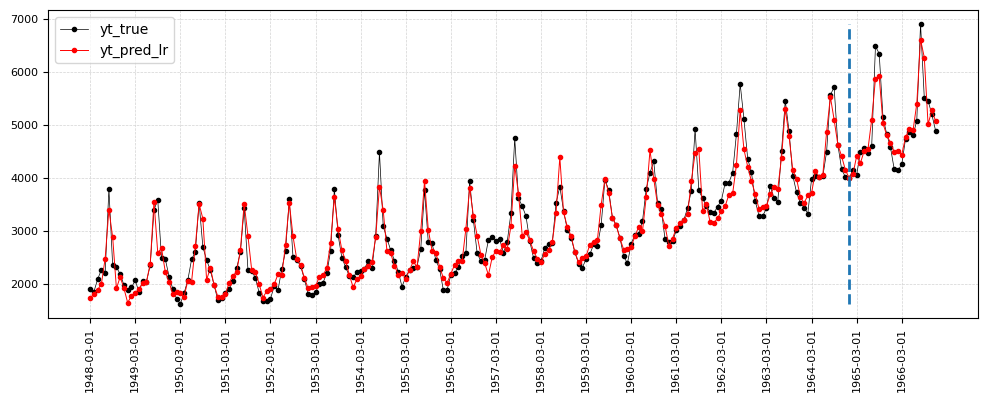

In [4]:
#
# Promedio de los pronosticos
#
from sklearn.linear_model import LinearRegression

model = LinearRegression()
X = df_dropna.drop(columns=["yt_true", "yt_pred_mean"])
y = df_dropna["yt_true"]
model.fit(X, y)
df_dropna["yt_pred_lr"] = model.predict(X)
functions.plot_time_series(df=df_dropna[["yt_true", "yt_pred_lr"]], yt_col="yt_true")
